# BRD4 natural-product docking: comprehensive quality control and sensitivity analysis
**26–27 November 2026 | BD1 (2YEL), BD2 (2YEM)**


This self-contained notebook reproduces the quantitative figures from the reported CHPC terminal outputs for 15 natural products. Primary grids and +4 Å expanded dimensions were evaluated with Vina 1.2.3, seed 2024, exhaustiveness 32, four CPUs, up to nine poses, and pH 7.5 preparations. Original grids remain primary. The source data below are transcribed terminal summaries, not independently re-run docking calculations. Expanded BD2 scores are reconstructed to 0.001 kcal/mol from reported expanded BD1 scores and BD1−BD2 differences; published summary statistics are checked. The 4 Å residue contacts are geometric contacts, not confirmed hydrogen bonds. No experimental binding or selectivity is implied. The reference redocking RMSD threshold is 2 Å; candidate pose differences and boundary margins use descriptive thresholds only. Single-seed grid comparisons do not establish multi-seed reproducibility.

**Figure standard:** Figentra v0.1.2, verified against https://github.com/peterDataScientia/figentra/blob/main/src/figentra/style.py. Approved typography, line widths, ticks, spines, background and PNG/PDF/SVG export settings are implemented explicitly so this notebook is self-contained. Canvas is adapted for multi-panel or dense figures; 130 × 100 mm is the default. Figure 5 panels A/B correspond to BD1/BD2. No numerical data were changed.

Sections 1–7 retain the historical grid sensitivity analysis. Sections 8–13 add ligand preparation sensitivity, NP01 protonation, all-ligand QC, corrected ranking and WSH audit. All source values are reported CHPC outputs or explicitly calculated from them; no new docking or MD is performed here.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from scipy.stats import spearmanr, kendalltau
from IPython.display import display, Image
from io import BytesIO

OUT = Path('figures'); OUT.mkdir(exist_ok=True)
# Approved Figentra v0.1.2 settings; self-contained implementation.
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':12,'axes.labelsize':15,'axes.labelweight':'bold','axes.linewidth':2.0,'xtick.labelsize':12,'ytick.labelsize':12,'legend.fontsize':11,'legend.frameon':False,'lines.linewidth':2,'figure.facecolor':'white','axes.facecolor':'white','savefig.facecolor':'white','svg.fonttype':'none','pdf.fonttype':42,'axes.grid':False,'figure.figsize':(130/25.4,100/25.4)})
B='#0866DD'; D='#F04C28'; G='#080F1D'; T='#14866D'; P='#8C49B8'
def mm(w=130,h=100): return (w/25.4,h/25.4)
def style_axes(ax):
    for side in ('top','right'): ax.spines[side].set_visible(False)
    for side in ('left','bottom'):
        ax.spines[side].set_visible(True); ax.spines[side].set_linewidth(2)
    ax.tick_params(axis='both',which='major',width=2,length=6,direction='out',labelsize=12)
    ax.minorticks_off(); ax.grid(False,which='both'); ax.set_facecolor('white'); ax.set_title('')
    for label in (ax.xaxis.label,ax.yaxis.label):
        label.set_fontsize(15); label.set_fontweight('bold')
    ax.xaxis.labelpad=7; ax.yaxis.labelpad=7
    for label in ax.get_xticklabels()+ax.get_yticklabels():
        label.set_fontsize(12); label.set_fontweight('bold')
    leg=ax.get_legend()
    if leg is not None:
        leg.set_frame_on(False)
        for label in leg.get_texts(): label.set_fontsize(11); label.set_fontweight('bold')
    return ax
def finish(fig,name):
    for ax in fig.axes: style_axes(ax)
    fig.tight_layout(pad=1.0,w_pad=1.5,h_pad=1.5)
    for ext in ('svg','pdf','png'): fig.savefig(OUT/(name+'.'+ext),dpi=600,facecolor='white')
    from IPython.display import SVG
    display(SVG(filename=str(OUT/(name+'.svg'))))
    plt.close(fig)
def panel(ax,letter): ax.text(-.12,1.04,letter,transform=ax.transAxes,fontsize=15,fontweight='bold',va='bottom')
ids=[f'NP{i:02d}' for i in range(1,16)]
x=np.arange(15)
orig1=[-7.731,-6.737,-6.513,-6.894,-6.719,-7.233,-6.329,-7.271,-8.174,-8.370,-8.519,-8.710,-7.842,-7.201,-7.260]
orig2=[-8.111,-6.861,-6.917,-6.624,-7.136,-7.755,-6.221,-6.960,-7.876,-8.408,-8.290,-8.299,-8.128,-7.409,-7.389]
exp1=[-8.049,-6.699,-6.446,-6.981,-6.670,-7.331,-6.212,-7.257,-8.337,-8.293,-8.221,-8.499,-7.962,-7.424,-7.203]
exp_delta=[.002,.105,.784,-.329,.363,.454,.029,-.260,.065,.117,.087,.640,.435,.010,.174]
exp2=np.round(np.array(exp1)-exp_delta,3)
df=pd.DataFrame(dict(Ligand=ids,BD1_original=orig1,BD2_original=orig2,BD1_expanded=exp1,BD2_expanded=exp2,diameter=[15.174,12.575,11.267,13.298,10.197,12.710,12.414,9.284,13.213,15.170,13.228,13.324,13.757,16.485,12.782],heavy_atoms=[34,27,26,25,21,23,27,21,43,42,43,42,29,33,24],formal_charge=[1]+[0]*14,partial_charge=[1.002,.002,0,.001,.001,.001,0,.001,0,-.001,-.001,0,-.003,-.001,.001],conversion_RMSD=[.00050,.00049,.00049,.00051,.00053,.00054,.00048,.00052,.00052,.00052,.00052,.00052,.00057,.00050,.00049],torsdof=[6,6,8,8,3,5,6,2,9,9,9,9,7,11,6],BD1_pose_RMSD=[.133,.114,.095,.704,4.493,1.895,.256,.236,.091,.154,.103,.090,.214,9.177,.184],BD2_pose_RMSD=[.425,.176,.094,1.106,.072,.107,1.896,.149,10.978,10.453,11.132,9.922,.225,.757,.118]))
df.to_csv(OUT/'ligand_summary.csv',index=False)
assert len(df)==15 and (abs(df.partial_charge-df.formal_charge)<=.05).all()
print('Ligand records:',len(df),'| charge QC: 15/15 | source identity QC: 15/15 (reported)')
print('Original poses: 270; expanded poses: 269; structural QC: 539/539 (reported).')

Ligand records: 15 | charge QC: 15/15 | source identity QC: 15/15 (reported)
Original poses: 270; expanded poses: 269; structural QC: 539/539 (reported).


## 1. Ligand preparation and search-space geometry
Diameters are maximum intramolecular distances of the prepared ligand, not a proof of fit for every conformer or orientation. Charge errors are PDBQT charge minus formal charge. Coordinate RMSD represents format conversion, not docking accuracy.
The later atom-type audit flagged six ligands; historical conversion QC did not establish complete chemical correctness.

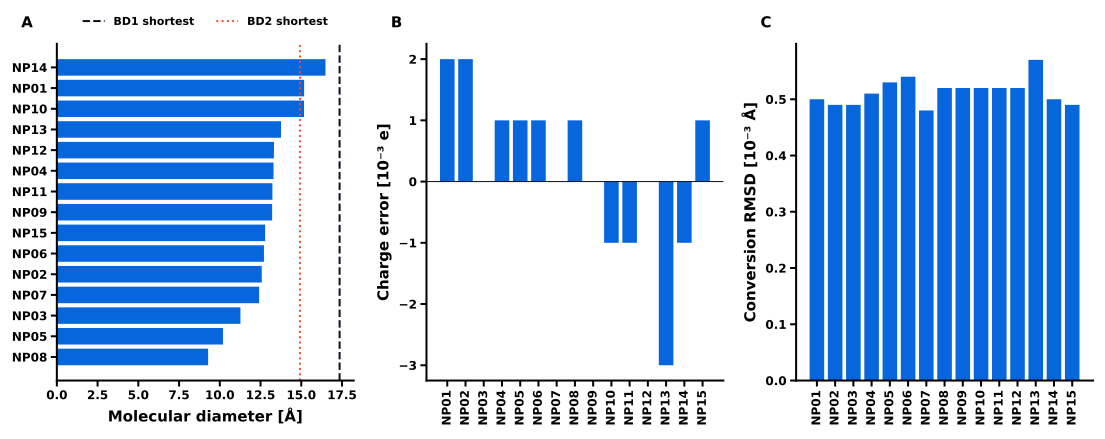

In [2]:
fig,ax=plt.subplots(1,3,figsize=mm(390,155))
order=np.argsort(df.diameter)
ax[0].barh(x,df.diameter.iloc[order],color=B); ax[0].set_yticks(x,df.Ligand.iloc[order]); ax[0].axvline(17.352,color=G,ls='--',label='BD1 shortest'); ax[0].axvline(14.917,color=D,ls=':',label='BD2 shortest'); ax[0].set_xlabel('Molecular diameter [Å]'); ax[0].legend(loc='lower center',bbox_to_anchor=(.5,1.02),ncol=2)
ax[1].bar(x,1000*(df.partial_charge-df.formal_charge),color=B); ax[1].axhline(0,color=G,lw=1); ax[1].set_ylabel('Charge error [10⁻³ e]'); ax[1].set_xticks(x,ids,rotation=90)
ax[2].bar(x,1000*df.conversion_RMSD,color=B); ax[2].set_ylabel('Conversion RMSD [10⁻³ Å]'); ax[2].set_xticks(x,ids,rotation=90)
for a,l in zip(ax,'ABC'): panel(a,l)
finish(fig,'01_ligand_qc')

## 2. Reference redocking validation
Symmetry-corrected heavy-atom RMSD to crystallographic WSH; no alignment. Both top-ranked poses pass under each grid protocol.

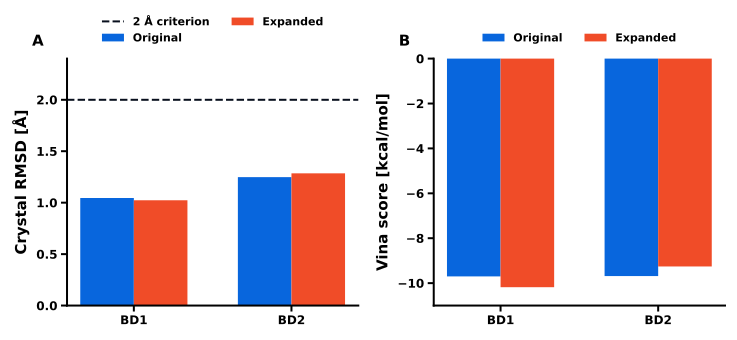

In [3]:
fig,ax=plt.subplots(1,2,figsize=mm(260,120)); q=np.arange(2); w=.34
for k,(a,b,ylabel) in enumerate([([1.045,1.248],[1.023,1.285],'Crystal RMSD [Å]'),([-9.700,-9.687],[-10.182,-9.260],'Vina score [kcal/mol]')]):
    ax[k].bar(q-w/2,a,w,label='Original',color=B); ax[k].bar(q+w/2,b,w,label='Expanded',color=D); ax[k].set_xticks(q,['BD1','BD2']); ax[k].set_ylabel(ylabel); panel(ax[k],'AB'[k])
ax[0].axhline(2,color=G,ls='--',label='2 Å criterion'); ax[0].set_ylim(0,2.4); ax[0].legend(loc='lower center',bbox_to_anchor=(.5,1.02),ncol=2); ax[1].legend(loc='lower center',bbox_to_anchor=(.5,1.02),ncol=2); ax[1].set_ylim(-11,0)
finish(fig,'02_redocking_validation')

## 3. Primary candidate docking scores
The WSH reference is plotted separately from the natural products; more negative scores are more favourable within this scoring model.

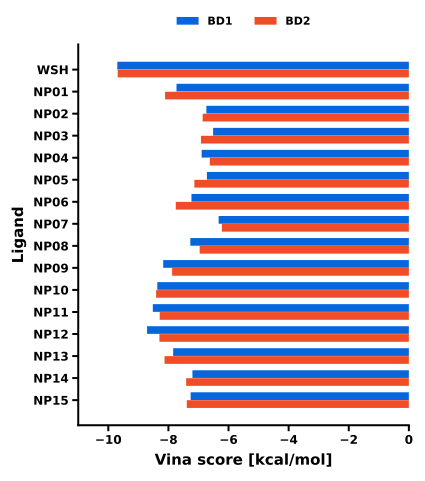

In [4]:
fig,ax=plt.subplots(figsize=mm(150,170)); y=np.arange(16); a=[-9.700]+orig1; b=[-9.687]+orig2
ax.barh(y-.18,a,.35,color=B,label='BD1'); ax.barh(y+.18,b,.35,color=D,label='BD2'); ax.set_yticks(y,['WSH']+ids); ax.invert_yaxis(); ax.set_xlabel('Vina score [kcal/mol]'); ax.set_ylabel('Ligand'); ax.legend(loc='lower center',bbox_to_anchor=(.5,1.02),ncol=2); ax.set_xlim(-11,0); finish(fig,'03_primary_scores')

## 4. Score and ranking sensitivity
Reconstructed BD2 expanded scores are checked against the reported summary. Ties are not interpreted as biological selectivity.

Domain  Spearman  p_rho  Kendall  p_tau    bias    MAE   RMSE  max_abs  top5_overlap
   BD1    0.9500    0.0   0.8286    0.0 -0.0054 0.1291 0.1578    0.318             4
   BD2    0.9607    0.0   0.8667    0.0 -0.1251 0.1560 0.2798    0.840             4


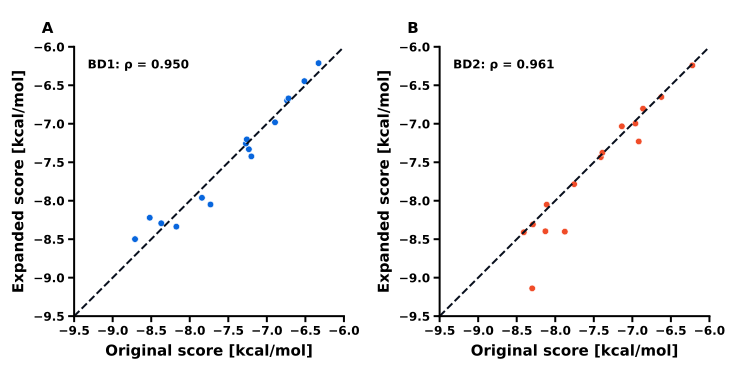

In [5]:
stats=[]
fig,ax=plt.subplots(1,2,figsize=mm(260,135))
for k,d in enumerate(['BD1','BD2']):
    a=df[d+'_original'].to_numpy(); b=df[d+'_expanded'].to_numpy(); delta=b-a; rho,p=spearmanr(a,b); tau,pt=kendalltau(a,b)
    topa=set(np.argsort(a)[:5]); topb=set(np.argsort(b)[:5]); stats.append([d,rho,p,tau,pt,delta.mean(),abs(delta).mean(),np.sqrt(np.mean(delta**2)),abs(delta).max(),len(topa&topb)])
    ax[k].scatter(a,b,s=44,color=[B,D][k],edgecolors='white',linewidth=.6); ax[k].plot([-9.5,-6],[-9.5,-6],ls='--',color=G); ax[k].set(xlim=(-9.5,-6),ylim=(-9.5,-6),xlabel='Original score [kcal/mol]',ylabel='Expanded score [kcal/mol]'); ax[k].set_aspect('equal'); ax[k].text(.05,.92,f'{d}: ρ = {rho:.3f}',transform=ax[k].transAxes,fontweight='bold'); panel(ax[k],'AB'[k])
s=pd.DataFrame(stats,columns=['Domain','Spearman','p_rho','Kendall','p_tau','bias','MAE','RMSE','max_abs','top5_overlap']); print(s.round(4).to_string(index=False)); s.to_csv(OUT/'score_statistics.csv',index=False)
np.testing.assert_allclose(s.Spearman,[.9500,.9607],atol=.0001); np.testing.assert_allclose(s.MAE,[.1291,.1560],atol=.0001)
finish(fig,'04_score_agreement')

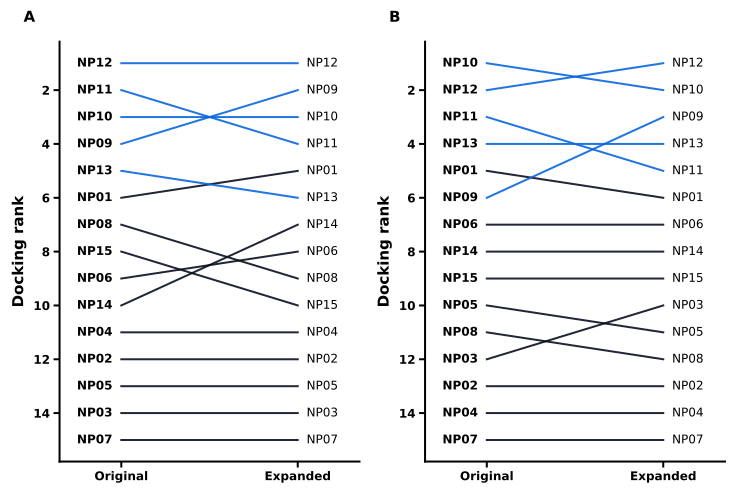

In [6]:
fig,ax=plt.subplots(1,2,figsize=mm(260,175));
for k,d in enumerate(['BD1','BD2']):
    a=df[d+'_original'].rank(method='min'); b=df[d+'_expanded'].rank(method='min');
    for i in range(15):
        ax[k].plot([0,1],[a[i],b[i]],color=B if i in [8,9,10,11,12] else G,alpha=.9,lw=2); ax[k].text(-.05,a[i],ids[i],ha='right',va='center',fontsize=12,fontweight='bold'); ax[k].text(1.05,b[i],ids[i],ha='left',va='center',fontsize=12)
    ax[k].set(xlim=(-.35,1.35),ylim=(15.8,.2),xticks=[0,1],xticklabels=['Original','Expanded'],ylabel='Docking rank'); ax[k].yaxis.set_major_locator(MaxNLocator(integer=True)); panel(ax[k],'AB'[k])
finish(fig,'05_rank_robustness')

Sign reversals: NP07, NP09, NP11, NP12


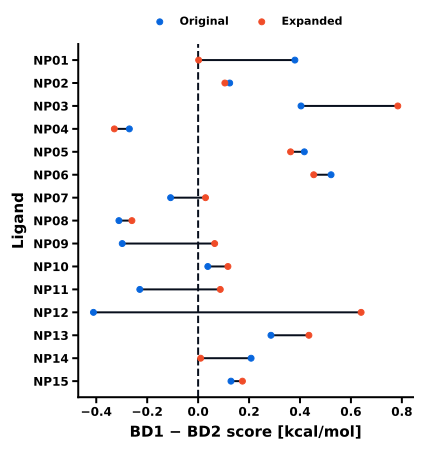

In [7]:
fig,ax=plt.subplots(figsize=mm(150,160)); o=np.array(orig1)-orig2; e=np.array(exp_delta); y=np.arange(15)
for i in range(15): ax.plot([o[i],e[i]],[i,i],color=G,lw=2)
ax.scatter(o,y,color=B,label='Original',zorder=3); ax.scatter(e,y,color=D,label='Expanded',zorder=3); ax.axvline(0,color=G,ls='--'); ax.set_yticks(y,ids); ax.invert_yaxis(); ax.set_xlabel('BD1 − BD2 score [kcal/mol]'); ax.set_ylabel('Ligand'); ax.legend(loc='lower center',bbox_to_anchor=(.5,1.02),ncol=2); print('Sign reversals:',', '.join(df.Ligand[o*e<0])); finish(fig,'06_domain_preference')

## 5. Binding-mode sensitivity
Symmetry-corrected top-ranked heavy-atom RMSD without fitting, as reported from CHPC. RMSD > 2 Å flags a descriptive pose change; not a failure criterion for unknown binding poses.

Stable top poses: 13 /15 BD1; 11 /15 BD2


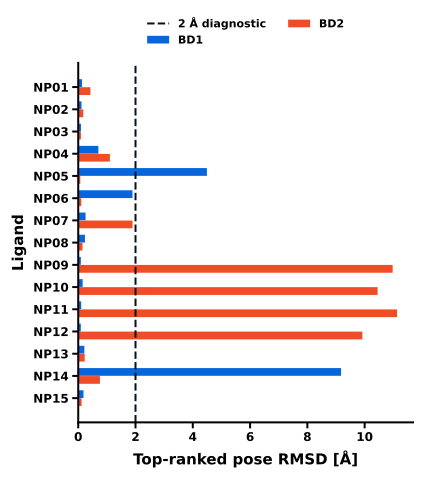

In [8]:
fig,ax=plt.subplots(figsize=mm(150,170)); y=np.arange(15); ax.barh(y-.18,df.BD1_pose_RMSD,.35,color=B,label='BD1'); ax.barh(y+.18,df.BD2_pose_RMSD,.35,color=D,label='BD2'); ax.axvline(2,color=G,ls='--',label='2 Å diagnostic'); ax.set_yticks(y,ids); ax.invert_yaxis(); ax.set_xlabel('Top-ranked pose RMSD [Å]'); ax.set_ylabel('Ligand'); ax.legend(loc='lower center',bbox_to_anchor=(.5,1.02),ncol=2); print('Stable top poses:',sum(df.BD1_pose_RMSD<=2),'/15 BD1;',sum(df.BD2_pose_RMSD<=2),'/15 BD2'); finish(fig,'07_pose_rmsd')

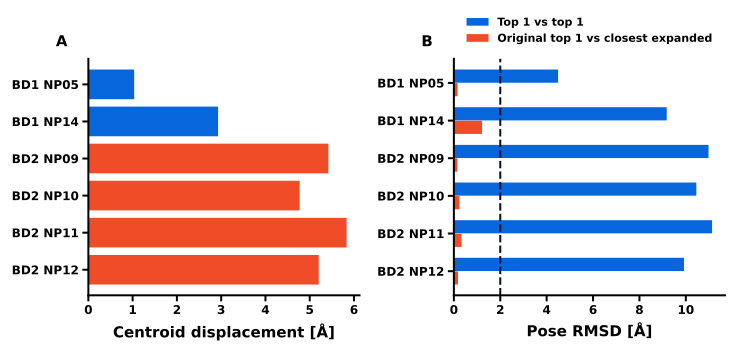

In [9]:
alt=pd.DataFrame({'Case':['BD1 NP05','BD1 NP14','BD2 NP09','BD2 NP10','BD2 NP11','BD2 NP12'],'Top1_RMSD':[4.493,9.177,10.978,10.453,11.132,9.922],'centroid_shift':[1.035,2.930,5.421,4.773,5.833,5.204],'recovered_RMSD':[.159,1.215,.149,.237,.333,.178],'expanded_mode':[2,2,3,4,3,5],'reverse_RMSD':[.278,2.322,7.614,8.408,7.224,7.036],'minimum_all_pairs':[.103,.106,.138,.120,.133,.178],'original_WSH_distance':[1.715,1.831,1.548,1.932,1.425,1.443],'expanded_WSH_distance':[.866,3.316,6.576,6.563,6.785,6.251],'original_WSH_Jaccard':[.538,.786,.786,.714,.769,.846],'expanded_WSH_Jaccard':[.538,.500,.500,.500,.467,.467],'cross_grid_Jaccard':[1,.5,.667,.583,.462,.538]}); alt.to_csv(OUT/'alternative_pose_summary.csv',index=False)
fig,ax=plt.subplots(1,2,figsize=mm(260,125)); y=np.arange(6)
ax[0].barh(y,alt.centroid_shift,color=[B]*2+[D]*4); ax[0].set_xlabel('Centroid displacement [Å]'); ax[1].barh(y-.18,alt.Top1_RMSD,.35,color=B,label='Top 1 vs top 1'); ax[1].barh(y+.18,alt.recovered_RMSD,.35,color=D,label='Original top 1 vs closest expanded'); ax[1].set_xlabel('Pose RMSD [Å]'); ax[1].axvline(2,color=G,ls='--'); ax[1].legend(loc='lower center',bbox_to_anchor=(.5,1.02))
for a,l in zip(ax,'AB'): a.set_yticks(y,alt.Case); a.invert_yaxis(); panel(a,l)
finish(fig,'08_alternative_pose_recovery')

## 6. Pocket occupancy and residue contact comparison
Contact sets are geometric heavy-atom contacts within 4 Å. Greater WSH similarity does not establish the correct pose.

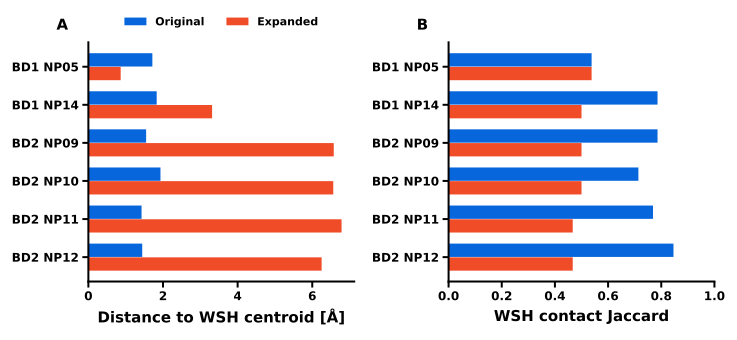

In [10]:
fig,ax=plt.subplots(1,2,figsize=mm(260,120)); y=np.arange(6)
for k,(a,b,l) in enumerate([(alt.original_WSH_distance,alt.expanded_WSH_distance,'Distance to WSH centroid [Å]'),(alt.original_WSH_Jaccard,alt.expanded_WSH_Jaccard,'WSH contact Jaccard')]):
    ax[k].barh(y-.18,a,.35,color=B,label='Original'); ax[k].barh(y+.18,b,.35,color=D,label='Expanded'); ax[k].set_yticks(y,alt.Case); ax[k].invert_yaxis(); ax[k].set_xlabel(l); panel(ax[k],'AB'[k])
ax[0].legend(loc='lower center',bbox_to_anchor=(.5,1.02),ncol=2); ax[1].set_xlim(0,1); finish(fig,'09_pocket_occupancy')

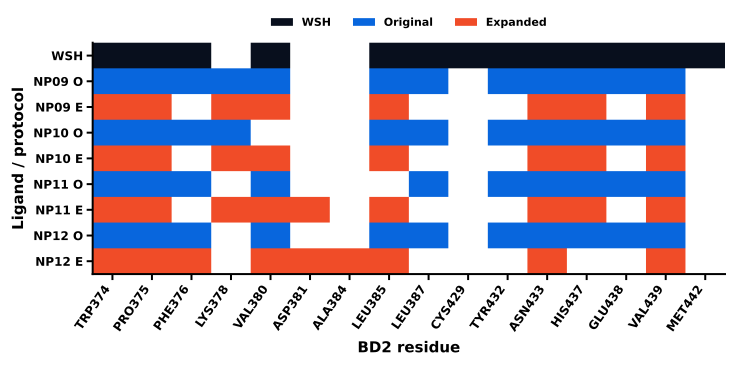

In [11]:
contacts={'WSH':[433,429,438,437,385,387,442,376,375,374,432,380,439], 'NP09 O':[433,438,437,385,387,378,376,375,374,432,380,439], 'NP09 E':[433,437,385,378,375,374,380,439], 'NP10 O':[433,438,437,385,387,378,376,375,374,432,439], 'NP10 E':[433,437,385,378,375,374,380,439], 'NP11 O':[433,438,437,387,376,375,374,432,380,439], 'NP11 E':[433,381,437,385,378,375,374,380,439], 'NP12 O':[433,438,437,385,387,376,375,374,432,380,439], 'NP12 E':[384,433,381,385,376,375,374,380,439]}
names={374:'TRP',375:'PRO',376:'PHE',378:'LYS',380:'VAL',381:'ASP',384:'ALA',385:'LEU',387:'LEU',429:'CYS',432:'TYR',433:'ASN',437:'HIS',438:'GLU',439:'VAL',442:'MET'}
res=sorted(names); matrix=np.array([[int(r in v) for r in res] for v in contacts.values()]); labels=[names[r]+str(r) for r in res]; pd.DataFrame(matrix,index=contacts,columns=labels).to_csv(OUT/'BD2_contact_matrix.csv')
from matplotlib.colors import ListedColormap
fig,ax=plt.subplots(figsize=mm(260,130)); typed=matrix*np.array([1]+[2,3]*4)[:,None]; ax.imshow(typed,aspect='auto',cmap=ListedColormap(['#ffffff',G,B,D]),vmin=0,vmax=3); ax.set_xticks(range(len(res)),labels,rotation=55,ha='right'); ax.set_yticks(range(len(contacts)),list(contacts)); ax.set_xlabel('BD2 residue'); 
from matplotlib.patches import Patch
ax.set_ylabel('Ligand / protocol')
ax.legend(handles=[Patch(facecolor=G,label='WSH'),Patch(facecolor=B,label='Original'),Patch(facecolor=D,label='Expanded')],loc='lower center',bbox_to_anchor=(.5,1.02),ncol=3)
finish(fig,'10_contact_fingerprint')

## 7. Effective-grid boundary assessment
Effective grid dimensions follow the previously used ceiling-to-0.375 Å convention. Near boundary means heavy-atom clearance < 1 Å with a 0.001 Å numerical tolerance for outside classification. These are diagnostic thresholds.

Domain Protocol  poses  near  outside  top1_near  median_top1_margin  near_pct
   BD1 Original    135    47        0          4              2.2065 34.814815
   BD1 Expanded    135    14        0          1              3.8915 10.370370
   BD2 Original    135    54        0          8              0.9335 40.000000
   BD2 Expanded    134    20        0          4              2.6060 14.925373


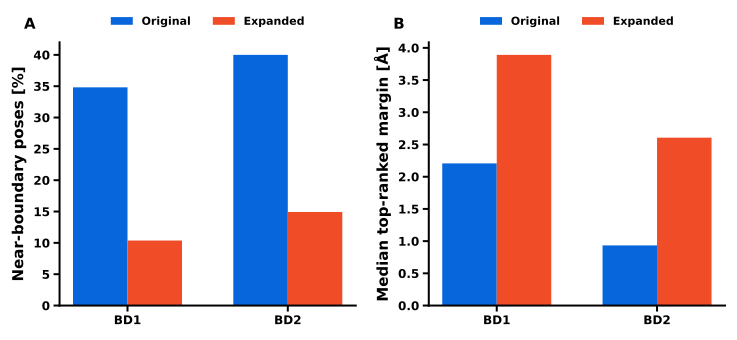

In [12]:
bound=pd.DataFrame({'Domain':['BD1','BD1','BD2','BD2'],'Protocol':['Original','Expanded']*2,'poses':[135,135,135,134],'near':[47,14,54,20],'outside':[0,0,0,0],'top1_near':[4,1,8,4],'median_top1_margin':[2.2065,3.8915,.9335,2.606]}); bound['near_pct']=100*bound.near/bound.poses; bound.to_csv(OUT/'boundary_summary.csv',index=False)
fig,ax=plt.subplots(1,2,figsize=mm(260,120)); q=np.arange(2); w=.34
for k,(col,lab) in enumerate([('near_pct','Near-boundary poses [%]'),('median_top1_margin','Median top-ranked margin [Å]')]):
    for i,prot in enumerate(['Original','Expanded']): ax[k].bar(q+(i-.5)*w,bound[bound.Protocol==prot][col],w,label=prot,color=[B,D][i]);
    ax[k].set_xticks(q,['BD1','BD2']); ax[k].set_ylabel(lab); ax[k].legend(loc='lower center',bbox_to_anchor=(.5,1.02),ncol=2); panel(ax[k],'AB'[k])
print(bound.to_string(index=False)); finish(fig,'11_boundary_comparison')

## Interpretation and limitations
Ranking was strongly concordant under the two grid sizes (Spearman 0.9500 and 0.9607); 4/5 top candidates were retained in each domain. NP10–NP12 were top-five in all four rankings. Top-ranked pose stability was 13/15 (BD1) and 11/15 (BD2). Four compounds reversed the sign of the domain score difference. All six original binding configurations were recovered in lower-ranked expanded modes, and the four BD2 biflavonoids showed displacement away from the WSH centroid while retaining some pocket contacts. The expanded protocol reduced near-boundary poses; none of the 539 reported poses lay outside the calculated effective grid. These are computational diagnostics, not experimental validation. Full coordinate-level reproduction and structural superpositions require the raw CHPC archive. NP01 optimization convergence was not supplied in the visible terminal output. No fabricated coordinates or energy landscape calculations are used.

## 8. NP01 chemical preparation and protonation
Meeko 0.6.1 / RDKit 2023.09.5 / Gemmi 0.6.7, Python 3.9.6. The neutral and protonated conformers were independently optimised. Neutral Meeko charge passed QC but its exact value was not included in the available terminal excerpt (NR).

,Method,State,Heavy atoms,Formal charge,PDBQT charge,Aromatic C,Tertiary N type,Polar H,QC
0,MGLTools,Neutral,34,0,1.002,6,N,1,FAIL
1,MGLTools,Protonated,34,1,1.002,12,N,2,FAIL
2,Meeko,Neutral,34,0,NaN,6,NA,1,PASS (reported)
3,Meeko,Protonated,34,1,0.999,6,N,2,PASS


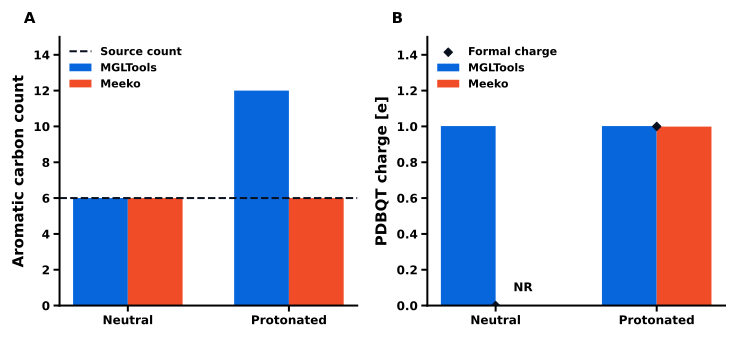

In [13]:
npqc=pd.DataFrame([['MGLTools','Neutral',34,0,1.002,6,'N',1,'FAIL'],['MGLTools','Protonated',34,1,1.002,12,'N',2,'FAIL'],['Meeko','Neutral',34,0,np.nan,6,'NA',1,'PASS (reported)'],['Meeko','Protonated',34,1,.999,6,'N',2,'PASS']],columns=['Method','State','Heavy atoms','Formal charge','PDBQT charge','Aromatic C','Tertiary N type','Polar H','QC'])
npqc.to_csv(OUT/'np01_chemical_QC.csv',index=False); display(npqc)
fig,ax=plt.subplots(1,2,figsize=mm(260,120)); q=np.arange(2); w=.34
for k,(col,lab) in enumerate([('Aromatic C','Aromatic carbon count'),('PDBQT charge','PDBQT charge [e]')]):
    for j,(s,c) in enumerate([('MGLTools',B),('Meeko',D)]):
        ax[k].bar(q+(j-.5)*w,npqc[npqc.Method==s][col],w,color=c,label=s)
    ax[k].set_xticks(q,['Neutral','Protonated']); ax[k].set_ylabel(lab); ax[k].set_ylim(0,15 if k==0 else 1.5); panel(ax[k],chr(65+k))
ax[0].axhline(6,color=G,ls='--',label='Source count'); ax[0].legend(loc='upper left'); ax[1].scatter(q,[0,1],color=G,marker='D',zorder=4,label='Formal charge'); ax[1].text(w/2,.08,'NR',ha='center',weight='bold'); ax[1].legend(loc='upper left'); finish(fig,'12_np01_chemical_QC')

## 9. NP01 protonation docking scores
Four original-grid Vina calculations (wet pH 7.5 receptors, exhaustiveness 32, seed 2024), nine modes each. Scores are not experimental affinities.

State,Neutral,Protonated,Delta
Domain,,,
BD1,-7.485,-7.729,-0.244
BD2,-7.779,-8.156,-0.377


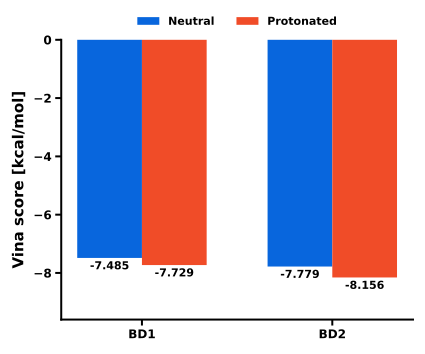

In [14]:
modes={('BD1','Neutral'):[-7.485,-7.344,-7.313,-7.310,-7.294,-7.034,-6.889,-6.837,-6.787],('BD1','Protonated'):[-7.729,-7.620,-7.438,-7.241,-7.082,-7.053,-6.994,-6.830,-6.809],('BD2','Neutral'):[-7.779,-7.610,-7.246,-7.119,-6.994,-6.915,-6.843,-6.841,-6.762],('BD2','Protonated'):[-8.156,-7.977,-7.882,-7.694,-7.523,-7.094,-6.991,-6.903,-6.841]}
mt=pd.DataFrame([(d,s,i+1,v) for (d,s),vs in modes.items() for i,v in enumerate(vs)],columns=['Domain','State','Mode','Score']); assert len(mt)==36
mt.to_csv(OUT/'np01_all_36_scores.csv',index=False)
pt=mt[mt.Mode==1].pivot(index='Domain',columns='State',values='Score'); pt['Delta']=pt.Protonated-pt.Neutral; pt.to_csv(OUT/'np01_protonation_scores.csv'); display(pt.round(3))
fig,ax=plt.subplots(figsize=mm(150,125)); q=np.arange(2); w=.34
for j,(s,c) in enumerate([('Neutral',B),('Protonated',D)]):
    bars=ax.bar(q+(j-.5)*w,pt[s],w,color=c,label=s); ax.bar_label(bars,fmt='%.3f',padding=3,fontsize=11,fontweight='bold')
ax.set_xticks(q,pt.index); ax.set_ylabel('Vina score [kcal/mol]'); ax.set_ylim(-9.6,0); ax.legend(loc='lower center',bbox_to_anchor=(.5,1.01),ncol=2); finish(fig,'13_np01_protonation_scores')

## 10. NP01 pose and pocket sensitivity
Symmetry-corrected heavy-atom RMSD without fitting. The 2 Å line is a descriptive diagnostic. Residue contacts are heavy-atom distances within 4 Å, not proof of hydrogen bonds.

,Domain,Comparison,RMSD [Å],Centroid shift [Å],Contact Jaccard
0,BD1,Original vs corrected,0.085,0.052,1.000
1,BD2,Original vs corrected,0.075,0.033,1.000
2,BD1,Neutral vs protonated,8.940,2.187,0.692
3,BD2,Neutral vs protonated,0.854,0.347,0.909


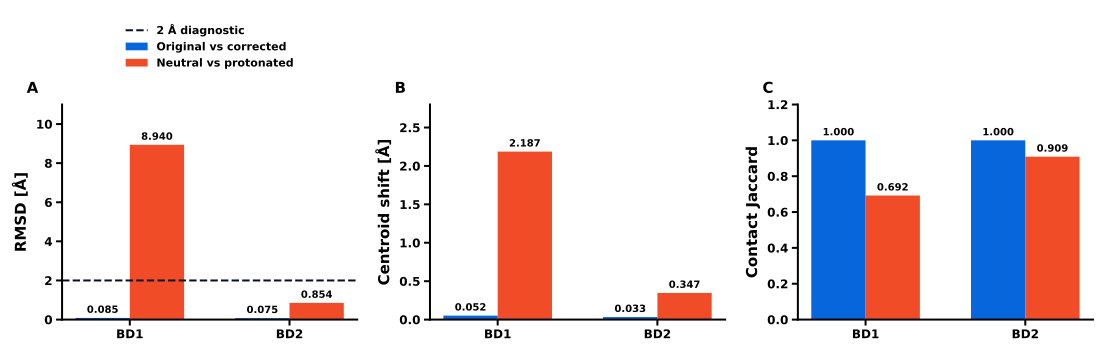

In [15]:
ps=pd.DataFrame([['BD1','Original vs corrected',.085,.052,1.],['BD2','Original vs corrected',.075,.033,1.],['BD1','Neutral vs protonated',8.940,2.187,.692],['BD2','Neutral vs protonated',.854,.347,.909]],columns=['Domain','Comparison','RMSD [Å]','Centroid shift [Å]','Contact Jaccard']); ps.to_csv(OUT/'np01_pose_comparison.csv',index=False); display(ps)
fig,ax=plt.subplots(1,3,figsize=mm(390,125)); q=np.arange(2); w=.34
for k,col in enumerate(ps.columns[2:]):
    for j,(s,c) in enumerate([('Original vs corrected',B),('Neutral vs protonated',D)]):
        bars=ax[k].bar(q+(j-.5)*w,ps[ps.Comparison==s][col],w,label=s,color=c); ax[k].bar_label(bars,fmt='%.3f',padding=3,fontsize=10,fontweight='bold')
    ax[k].set_xticks(q,['BD1','BD2']); ax[k].set_ylabel(col); ax[k].set_ylim(0,[11,2.8,1.2][k]); panel(ax[k],chr(65+k))
ax[0].axhline(2,ls='--',color=G,label='2 Å diagnostic'); ax[0].legend(loc='lower center',bbox_to_anchor=(.5,1.12)); finish(fig,'14_np01_pose_sensitivity')

,Domain,State,Contacts,Shared WSH contacts,WSH Jaccard,Residues
0,BD1,Original,11,8,0.571,ASN140 ASP144 ASP145 GLN85 ILE146 LEU92 LEU94 ...
1,BD1,Neutral,11,9,0.692,ASN140 ASP144 ASP145 ILE146 LEU92 MET149 PRO82...
2,BD1,Protonated,11,8,0.571,ASN140 ASP144 ASP145 GLN85 ILE146 LEU92 LEU94 ...
3,BD2,Original,11,9,0.600,ASN433 LEU385 LEU387 LYS378 PHE376 PRO375 TRP3...
4,BD2,Neutral,10,8,0.533,ASN433 LEU385 LEU387 LYS378 PHE376 PRO375 TRP3...
5,BD2,Protonated,11,9,0.600,ASN433 LEU385 LEU387 LYS378 PHE376 PRO375 TRP3...


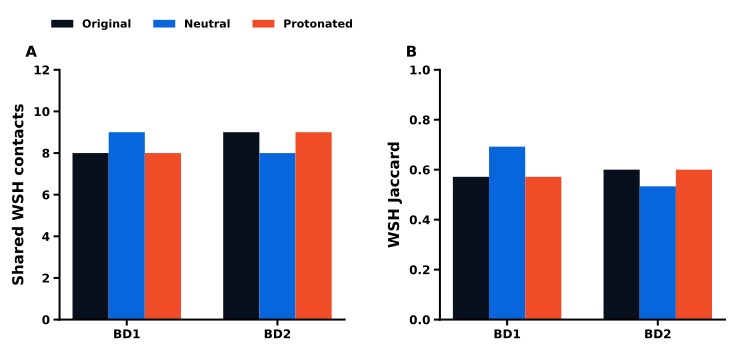

In [16]:
sets={('BD1','Original'):'ASN140 ASP144 ASP145 GLN85 ILE146 LEU92 LEU94 PRO82 TRP81 TYR139 TYR97',('BD1','Neutral'):'ASN140 ASP144 ASP145 ILE146 LEU92 MET149 PRO82 TRP81 TYR139 TYR97 VAL87',('BD1','Protonated'):'ASN140 ASP144 ASP145 GLN85 ILE146 LEU92 LEU94 PRO82 TRP81 TYR139 TYR97',('BD2','Original'):'ASN433 LEU385 LEU387 LYS378 PHE376 PRO375 TRP374 TYR390 TYR432 VAL380 VAL439',('BD2','Neutral'):'ASN433 LEU385 LEU387 LYS378 PHE376 PRO375 TRP374 TYR390 TYR432 VAL439',('BD2','Protonated'):'ASN433 LEU385 LEU387 LYS378 PHE376 PRO375 TRP374 TYR390 TYR432 VAL380 VAL439'}
ref={'BD1':set('ASN140 ASP145 ILE146 LEU92 LEU94 MET149 PHE83 PRO82 TRP81 TYR139 VAL87'.split()),'BD2':set('ASN433 CYS429 GLU438 HID437 LEU385 LEU387 MET442 PHE376 PRO375 TRP374 TYR432 VAL380 VAL439'.split())}
ct=pd.DataFrame([[d,s,len(set(v.split())),len(set(v.split())&ref[d]),len(set(v.split())&ref[d])/len(set(v.split())|ref[d]),v] for (d,s),v in sets.items()],columns=['Domain','State','Contacts','Shared WSH contacts','WSH Jaccard','Residues']); ct.to_csv(OUT/'np01_contact_sets.csv',index=False); display(ct.round(3))
fig,ax=plt.subplots(1,2,figsize=mm(260,125)); q=np.arange(2); w=.24
for k,col in enumerate(['Shared WSH contacts','WSH Jaccard']):
    for j,(s,c) in enumerate([('Original',G),('Neutral',B),('Protonated',D)]): ax[k].bar(q+(j-1)*w,ct[ct.State==s][col],w,label=s,color=c)
    ax[k].set_xticks(q,['BD1','BD2']); ax[k].set_ylabel(col); ax[k].set_ylim(0,12 if k==0 else 1); panel(ax[k],chr(65+k))
ax[0].legend(loc='lower center',bbox_to_anchor=(.5,1.12),ncol=3); finish(fig,'15_np01_WSH_contact_overlap')

## 11. Chemical audit of all 15 ligands
REVIEW does not necessarily mean chemical invalidity. NP03 nitrogen typing and NP13 torsional flexibility are method-dependent differences requiring review.

,Ligand,Status,Flag,Changed heavy-atom types,Atom changes
0,NP01,REVIEW,Aromaticity; atom typing,6,23:C:A→C;24:C:A→C;25:C:A→C;28:C:A→C;30:C:A→C;3...
1,NP02,PASS_BASIC,None reported,0,
2,NP03,REVIEW,Nitrogen typing,1,24:N:NA→N
3,NP04,PASS_BASIC,None reported,0,
4,NP05,PASS_BASIC,None reported,0,
5,NP06,PASS_BASIC,None reported,0,
6,NP07,REVIEW,Aromaticity; atom typing,3,9:C:C→A;11:C:C→A;14:C:C→A
7,NP08,REVIEW,Aromaticity; atom typing,2,20:C:A→C;21:C:A→C
8,NP09,PASS_BASIC,None reported,0,
9,NP10,PASS_BASIC,None reported,0,


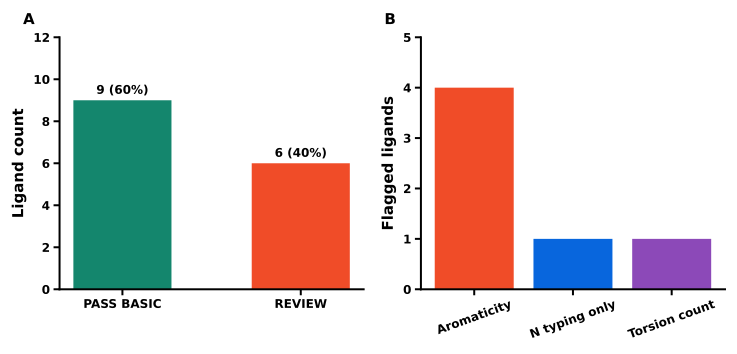

In [17]:
flags={'NP01':('Aromaticity; atom typing',6,'23:C:A→C;24:C:A→C;25:C:A→C;28:C:A→C;30:C:A→C;31:C:A→C'),'NP03':('Nitrogen typing',1,'24:N:NA→N'),'NP07':('Aromaticity; atom typing',3,'9:C:C→A;11:C:C→A;14:C:C→A'),'NP08':('Aromaticity; atom typing',2,'20:C:A→C;21:C:A→C'),'NP12':('Aromaticity; atom typing',3,'7:C:C→A;8:C:C→A;9:C:C→A'),'NP13':('Torsion count',0,'')}
audit=pd.DataFrame([[i,'REVIEW' if i in flags else 'PASS_BASIC',*flags.get(i,('None reported',0,''))] for i in ids],columns=['Ligand','Status','Flag','Changed heavy-atom types','Atom changes']); audit.to_csv(OUT/'ligand_audit_summary.csv',index=False); display(audit)
fig,ax=plt.subplots(1,2,figsize=mm(260,125)); bars=ax[0].bar(['PASS BASIC','REVIEW'],[9,6],color=[T,D],width=.55); ax[0].bar_label(bars,labels=['9 (60%)','6 (40%)'],padding=4,fontweight='bold'); ax[0].set_ylabel('Ligand count'); ax[0].set_ylim(0,12); ax[0].yaxis.set_major_locator(MaxNLocator(integer=True))
ax[1].bar(['Aromaticity','N typing only','Torsion count'],[4,1,1],color=[D,B,P]); ax[1].set_ylabel('Flagged ligands'); ax[1].set_ylim(0,5); ax[1].tick_params(axis='x',labelrotation=20); ax[1].yaxis.set_major_locator(MaxNLocator(integer=True)); panel(ax[0],'A'); panel(ax[1],'B'); finish(fig,'16_ligand_audit')

## 12. Selective re-docking and ranking robustness
Six flagged ligands have paired original/Meeko scores (12 systems). NP01 is +1. Nine other ligands retain original scores; this is a mixed-preparation sensitivity analysis, not a fully uniform Meeko dataset. Expanded-grid scores were not corrected.

Pooled paired MAE: 0.1131 RMSE: 0.1832


,Domain,Ligand,Original,Updated,Preparation,Delta,Original rank,Updated rank
0,BD1,NP01,-7.731,-7.729,Meeko,0.002,6,6
2,BD1,NP03,-6.513,-6.341,Meeko,0.172,14,14
6,BD1,NP07,-6.329,-6.251,Meeko,0.078,15,15
7,BD1,NP08,-7.271,-7.271,Meeko,0.000,7,7
11,BD1,NP12,-8.710,-8.442,Meeko,0.268,1,2
12,BD1,NP13,-7.842,-7.868,Meeko,-0.026,5,5
15,BD2,NP01,-8.111,-8.156,Meeko,-0.045,5,5
17,BD2,NP03,-6.917,-6.916,Meeko,0.001,12,12
21,BD2,NP07,-6.221,-6.481,Meeko,-0.260,15,15
22,BD2,NP08,-6.960,-6.960,Meeko,0.000,11,11


,Domain,Paired n,MAE,RMSE,Max abs change,Spearman rho,Kendall tau,Top5 overlap
0,BD1,6,0.0910,0.1343,0.268,0.9964,0.9810,5
1,BD2,6,0.1352,0.2215,0.473,0.9786,0.9429,5


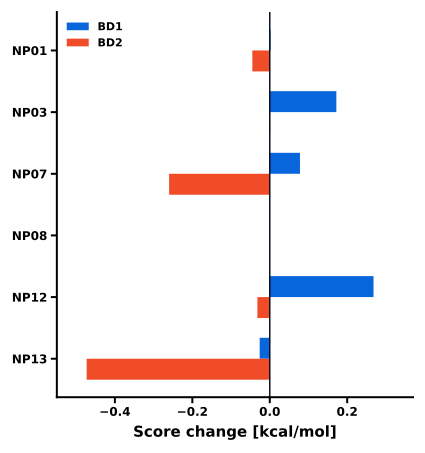

In [18]:
changes={'NP01':(-7.729,-8.156),'NP03':(-6.341,-6.916),'NP07':(-6.251,-6.481),'NP08':(-7.271,-6.960),'NP12':(-8.442,-8.331),'NP13':(-7.868,-8.601)}
updated=pd.DataFrame([(d,i,old,changes[i][k] if i in changes else old,'Meeko' if i in changes else 'Original') for k,(d,vs) in enumerate([('BD1',orig1),('BD2',orig2)]) for i,old in zip(ids,vs)],columns=['Domain','Ligand','Original','Updated','Preparation']); updated['Delta']=updated.Updated-updated.Original
updated['Original rank']=updated.groupby('Domain').Original.rank(method='min').astype(int); updated['Updated rank']=updated.groupby('Domain').Updated.rank(method='min').astype(int)
paired=updated[updated.Preparation=='Meeko'].copy(); assert len(paired)==12; paired.to_csv(OUT/'preparation_paired_scores.csv',index=False); updated.to_csv(OUT/'updated_primary_scores.csv',index=False); display(paired.round(3))
summary=[]
for d,g in updated.groupby('Domain'):
    p=paired[paired.Domain==d]; delta=p.Delta.to_numpy(); old=set(g.nsmallest(5,'Original').Ligand); new=set(g.nsmallest(5,'Updated').Ligand)
    summary.append([d,len(p),np.mean(abs(delta)),np.sqrt(np.mean(delta**2)),max(abs(delta)),spearmanr(g.Original,g.Updated)[0],kendalltau(g.Original,g.Updated)[0],len(old&new)])
prepstats=pd.DataFrame(summary,columns=['Domain','Paired n','MAE','RMSE','Max abs change','Spearman rho','Kendall tau','Top5 overlap']); prepstats.to_csv(OUT/'preparation_ranking_statistics.csv',index=False); display(prepstats.round(4)); assert round(prepstats.loc[prepstats.Domain=='BD2','Spearman rho'].iloc[0],4)==.9786
print('Pooled paired MAE:',round(paired.Delta.abs().mean(),4),'RMSE:',round(np.sqrt((paired.Delta**2).mean()),4))
fig,ax=plt.subplots(figsize=mm(150,160)); y=np.arange(6); w=.34
for j,(d,c) in enumerate([('BD1',B),('BD2',D)]): ax.barh(y+(j-.5)*w,paired[paired.Domain==d].Delta,w,color=c,label=d)
ax.set_yticks(y,list(changes)); ax.invert_yaxis(); ax.axvline(0,color=G,lw=1.5); ax.set_xlim(-.55,.37); ax.set_xlabel('Score change [kcal/mol]'); ax.legend(loc='upper left'); finish(fig,'17_preparation_score_changes')

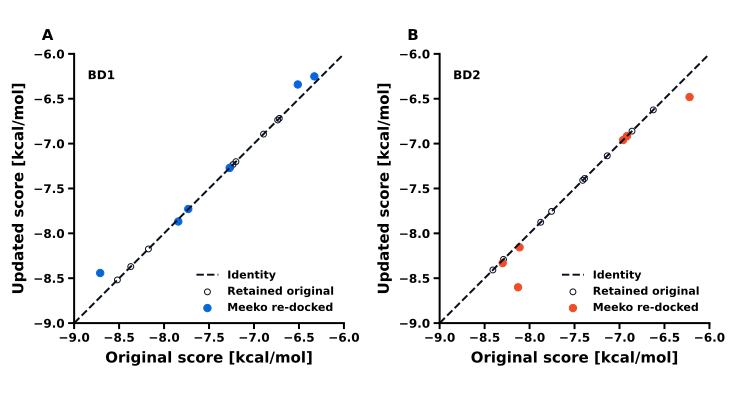

In [19]:
fig,ax=plt.subplots(1,2,figsize=mm(260,140))
for k,(d,g) in enumerate(updated.groupby('Domain')):
    p=g[g.Preparation=='Meeko']; o=g[g.Preparation=='Original']; a=ax[k]; a.plot([-9,-6],[-9,-6],ls='--',color=G,label='Identity'); a.scatter(o.Original,o.Updated,s=35,facecolors='none',edgecolors=G,label='Retained original'); a.scatter(p.Original,p.Updated,s=55,color=B if k==0 else D,label='Meeko re-docked'); a.set(xlabel='Original score [kcal/mol]',ylabel='Updated score [kcal/mol]',xlim=(-9,-6),ylim=(-9,-6)); a.set_aspect('equal'); panel(a,chr(65+k)); a.text(.05,.94,d,transform=a.transAxes,weight='bold',va='top'); a.legend(loc='lower right')
finish(fig,'18_preparation_score_agreement')

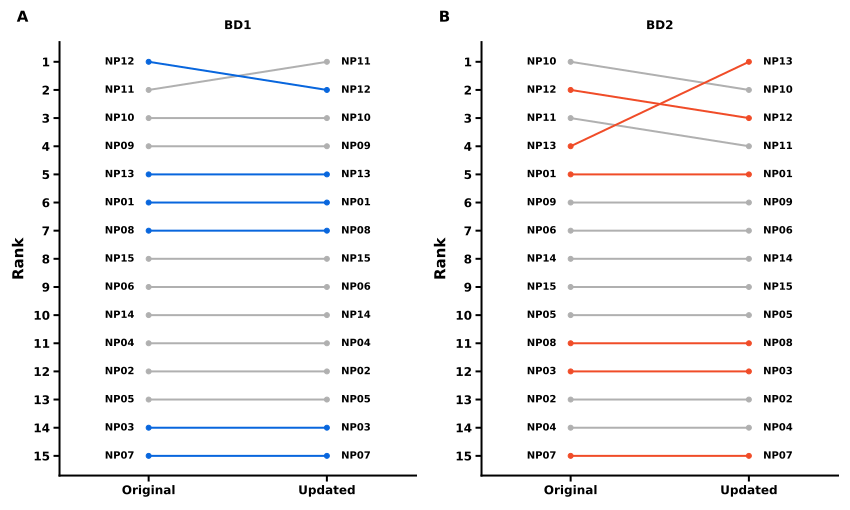

,Domain,Ligand,Original,Updated,Preparation,Delta,Original rank,Updated rank
10,BD1,NP11,-8.519,-8.519,Original,0.000,2,1
11,BD1,NP12,-8.710,-8.442,Meeko,0.268,1,2
9,BD1,NP10,-8.370,-8.370,Original,0.000,3,3
8,BD1,NP09,-8.174,-8.174,Original,0.000,4,4
12,BD1,NP13,-7.842,-7.868,Meeko,-0.026,5,5
0,BD1,NP01,-7.731,-7.729,Meeko,0.002,6,6
7,BD1,NP08,-7.271,-7.271,Meeko,0.000,7,7
14,BD1,NP15,-7.260,-7.260,Original,0.000,8,8
5,BD1,NP06,-7.233,-7.233,Original,0.000,9,9
13,BD1,NP14,-7.201,-7.201,Original,0.000,10,10


In [20]:
fig,ax=plt.subplots(1,2,figsize=mm(300,180))
for k,(d,g) in enumerate(updated.groupby('Domain')):
    a=ax[k]
    for _,v in g.iterrows():
        c=(B if k==0 else D) if v.Preparation=='Meeko' else '#B0B0B0'; a.plot([0,1],[v['Original rank'],v['Updated rank']],color=c,lw=2); a.scatter([0,1],[v['Original rank'],v['Updated rank']],color=c,s=25); a.text(-.08,v['Original rank'],v.Ligand,ha='right',va='center',fontsize=10,fontweight='bold'); a.text(1.08,v['Updated rank'],v.Ligand,ha='left',va='center',fontsize=10,fontweight='bold')
    a.set_xticks([0,1],['Original','Updated']); a.set_xlim(-.5,1.5); a.set_ylim(15.7,.3); a.set_yticks(range(1,16)); a.set_ylabel('Rank'); a.text(.5,1.03,d,transform=a.transAxes,ha='center',weight='bold'); panel(a,chr(65+k))
finish(fig,'19_preparation_ranking'); display(updated.sort_values(['Domain','Updated rank']).round(3))

## 13. WSH reference audit and MD readiness
Shared WSH InChIKey TUWDLUFFAHHNEF-QHCPKHFHSA-N. Both heavy-atom mappings passed, with no changed atom types. This is docking QC, not force-field validation.

In [21]:
wsh=pd.DataFrame([[d,32,0,20,.002,-.004,5,5,0,'PASS'] for d in ['BD1','BD2']],columns=['Domain','Heavy atoms','Formal charge','Aromatic C','Original charge','Meeko charge','Original torsions','Meeko torsions','Changed types','Mapping']); wsh.to_csv(OUT/'WSH_reference_QC.csv',index=False); display(wsh)
md=pd.DataFrame([['NP01','Psychotrine','Predicted BD1-selective',1,'Corrected Meeko'],['NP02','Isosinensetin','Predicted BD2-selective',0,'Original basic QC PASS'],['NP09','Sciadopitysin','Predicted dual',0,'Original basic QC PASS'],['WSH','Reference','Reference inhibitor',0,'Crystal coordinates']],columns=['ID','Compound','QSAR-based role','Formal charge','Starting structure']); md.to_csv(OUT/'MD_candidate_plan.csv',index=False); display(md); print('Eight planned complexes; MD parameterisation pending.')

Eight planned complexes; MD parameterisation pending.


,Domain,Heavy atoms,Formal charge,Aromatic C,Original charge,Meeko charge,Original torsions,Meeko torsions,Changed types,Mapping
0,BD1,32,0,20,0.002,-0.004,5,5,0,PASS
1,BD2,32,0,20,0.002,-0.004,5,5,0,PASS


,ID,Compound,QSAR-based role,Formal charge,Starting structure
0,NP01,Psychotrine,Predicted BD1-selective,1,Corrected Meeko
1,NP02,Isosinensetin,Predicted BD2-selective,0,Original basic QC PASS
2,NP09,Sciadopitysin,Predicted dual,0,Original basic QC PASS
3,WSH,Reference,Reference inhibitor,0,Crystal coordinates


## Interpretation and limitations of the update
NP01 corrected protonated poses closely agree with original poses (0.085 Å BD1; 0.075 Å BD2). Neutral versus protonated poses differ in BD1 but not BD2; separately optimised conformers prevent attributing all effects solely to protonation. Four ligands were flagged for aromaticity, one for nitrogen typing alone and one for torsion count. All 12 paired scores differ by less than 0.5 kcal/mol; BD2 retains all five top-ranked ligands but NP13 moves to first. Full pose-comparison results for NP03/07/08/12/13 were not provided, so their RMSDs and contacts are not fabricated. Experimental pKa has not been established; NP01 protonation is provisional. Historical original-grid and expanded-grid results remain separate from the mixed-preparation update. No MD simulations or topology validation have been performed.

Provenance: user-reported CHPC outputs, 26–27 November 2026. Figentra style: https://github.com/peterDataScientia/figentra/blob/main/src/figentra/style.py (blob c3a55bf9c4740c4d1bc3b892ca8ff91554f73abf).